# Rice classification: all ten algorithms

Problem → data → preprocessing → models → results → team conclusion.

This is the combined Review 2 classification submission, including rerun Part A models for a controlled comparison.

## Data audit and exploratory plots
Median imputation, 1.5-IQR clipping and StandardScaler are fitted inside each CV training fold. Compactness = 4π Area / Perimeter² matches Review 1 feature engineering; identifiers are excluded before duplicate removal. All models use the same stratified 80:20 split (seed 42). GridSearchCV uses five stratified folds on training data and weighted F1. Held-out data is reserved for final reporting. Bagging explicitly uses a Decision Tree base estimator. No warnings or metric failures are silently suppressed.

Shape: (1900, 12) | Exact duplicates: 0
After cleaning: (1900, 12) | Train: 1520 | Test: 380


,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,18057,9429,174.671378,69.661360,0.917032,9752,109.569045,0.644938,406.975,0.715385,2.507436,0
1,3257,5842,145.807572,51.673280,0.935096,6020,86.245379,0.641978,330.790,0.670914,2.821721,1
2,17107,8359,158.012446,67.848264,0.903121,8540,103.164962,0.666268,370.413,0.765582,2.328909,0
3,9811,6493,167.571643,50.974529,0.952610,6737,90.923838,0.796687,366.921,0.606052,3.287360,1
4,9564,5594,153.172203,47.071526,0.951609,5770,84.394917,0.496847,337.176,0.618328,3.254031,1


,dtype,missing
id,int64,0
Area,int64,0
MajorAxisLength,float64,0
MinorAxisLength,float64,0
Eccentricity,float64,0
ConvexArea,int64,0
EquivDiameter,float64,0
Extent,float64,0
Perimeter,float64,0
Roundness,float64,0


,Rows
Class,
1,1037
0,863


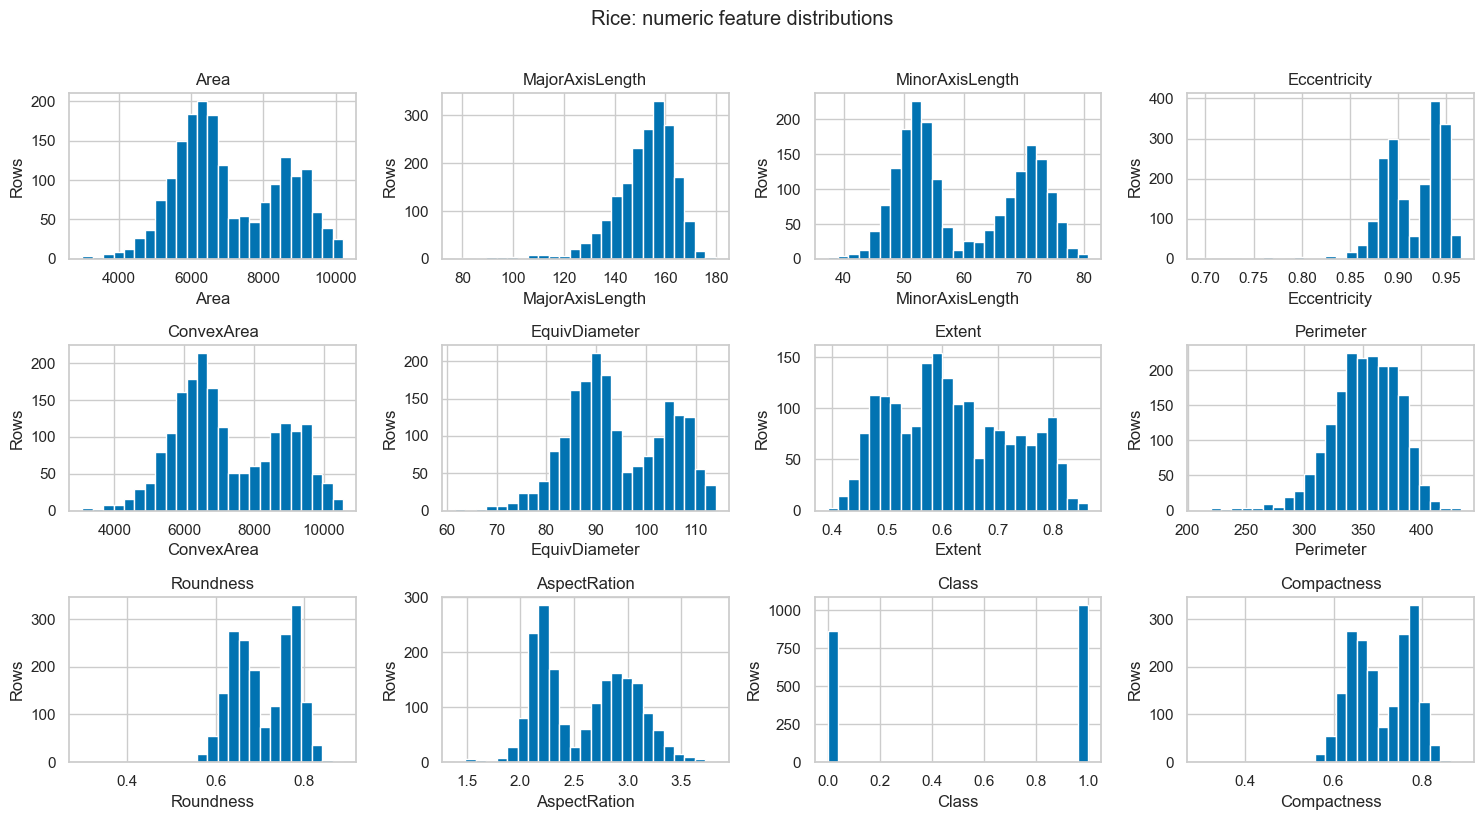

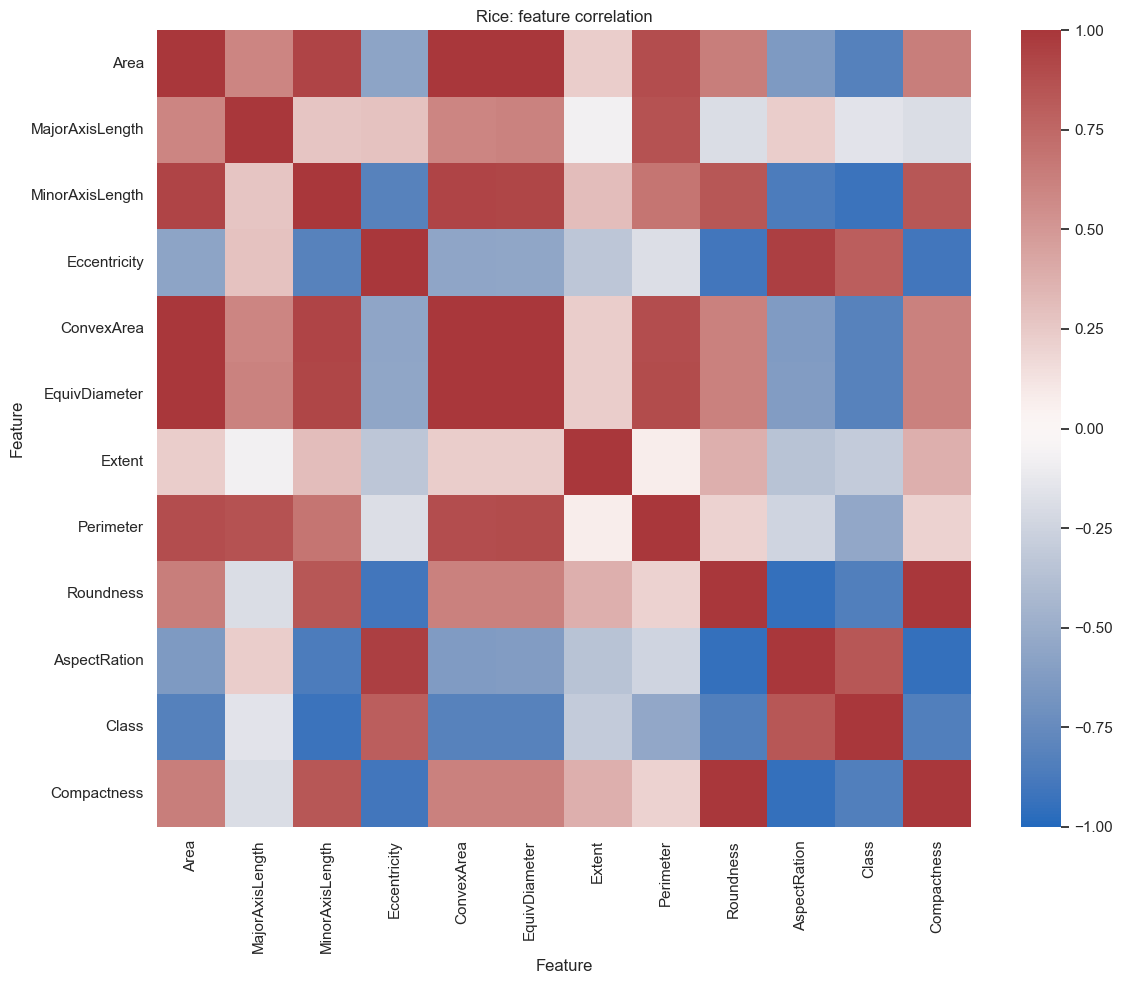

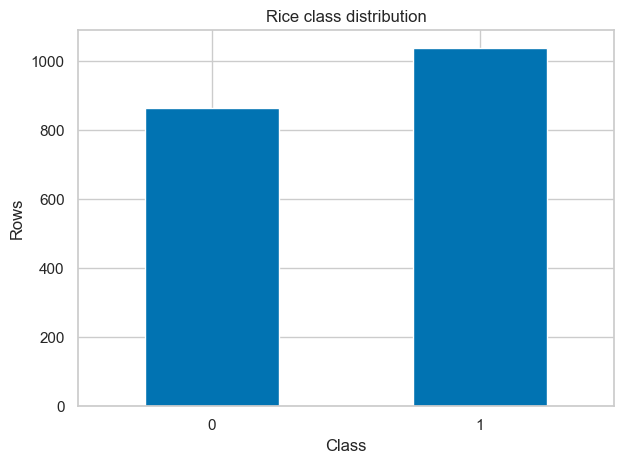

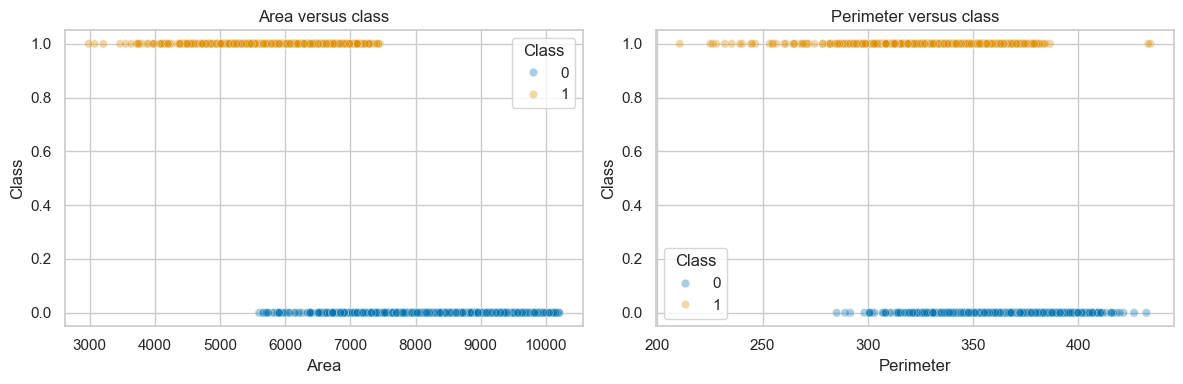

In [1]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'r2' / 'review2_pipeline.py').is_file())
sys.path.insert(0, str(root / 'r2'))
import review2_pipeline as review

data = review.rice_data(show_eda=True)

## Method notes
Logistic coefficients and odds ratios refer to one unit of the clipped, standardized input. KNN compares Euclidean and Manhattan distances and neighborhood sizes. Gaussian Naive Bayes assumes conditional feature independence given class; correlated shape features can violate this assumption. SVC tunes C/kernel after fold-specific scaling. Decision Tree includes a tree visualization. Model selection is by training CV weighted F1; held-out scores are reported without choosing hyperparameters from them.

## Logistic Regression
Train baseline, tune in five folds, display metrics and inspect held-out errors.

Best parameters: {'model__C': 1} | CV weighted F1: 0.9907883773281083


,Stage,Accuracy,Precision,Recall,F1_weighted,ROC_AUC
0,Baseline,0.98158,0.98187,0.98158,0.98155,0.99595
1,Tuned,0.98158,0.98187,0.98158,0.98155,0.99595


,Metric,Baseline,Tuned,Change
0,Accuracy,0.981579,0.981579,0.0
1,Precision,0.981873,0.981873,0.0
2,Recall,0.981579,0.981579,0.0
3,F1_weighted,0.981554,0.981554,0.0
4,ROC_AUC,0.995951,0.995951,0.0


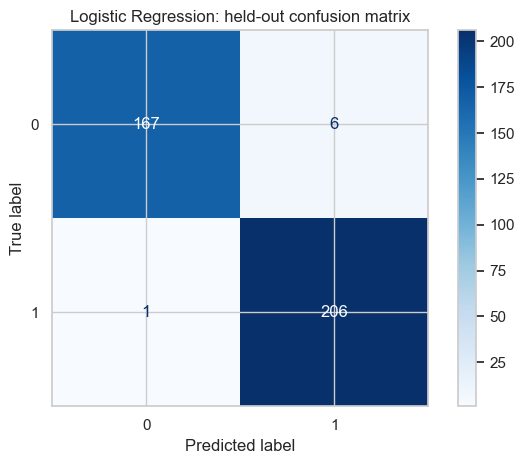

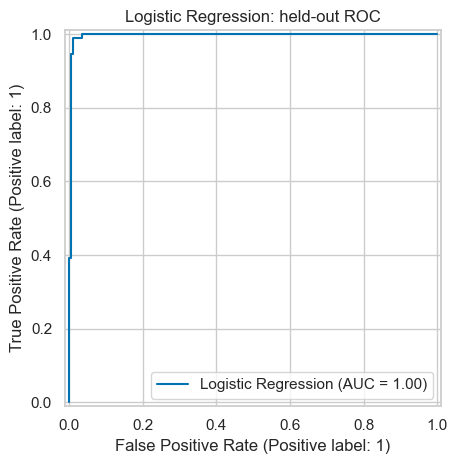

,Feature,Coefficient,Odds_ratio
0,Area,-1.403525,0.245729
1,MajorAxisLength,1.525176,4.595954
2,MinorAxisLength,-1.467596,0.230479
3,Eccentricity,-0.138113,0.871000
4,ConvexArea,-1.505894,0.221819
5,EquivDiameter,-1.626131,0.196689
6,Extent,0.161946,1.175797
7,Perimeter,-0.402952,0.668344
8,Roundness,-1.071937,0.342345
9,AspectRation,0.931928,2.539401


In [2]:
result = review.run_classifier('Logistic Regression', data)

## K-Nearest Neighbors
Train baseline, tune in five folds, display metrics and inspect held-out errors.

Best parameters: {'model__metric': 'euclidean', 'model__n_neighbors': 15, 'model__weights': 'uniform'} | CV weighted F1: 0.9907851163066747


,Stage,Accuracy,Precision,Recall,F1_weighted,ROC_AUC
0,Baseline,0.97895,0.97912,0.97895,0.97892,0.98217
1,Tuned,0.98158,0.98187,0.98158,0.98155,0.98951


,Metric,Baseline,Tuned,Change
0,Accuracy,0.978947,0.981579,0.002632
1,Precision,0.979122,0.981873,0.002751
2,Recall,0.978947,0.981579,0.002632
3,F1_weighted,0.978925,0.981554,0.002629
4,ROC_AUC,0.982170,0.989514,0.007344


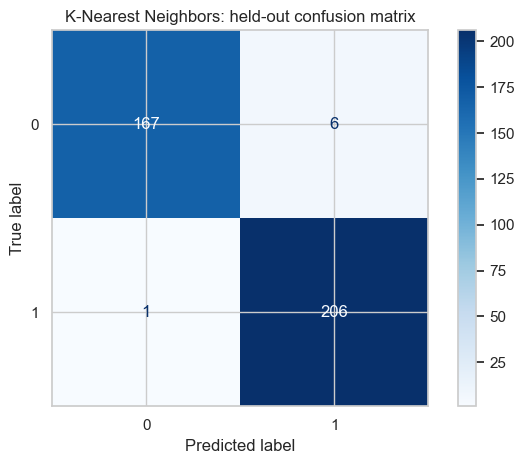

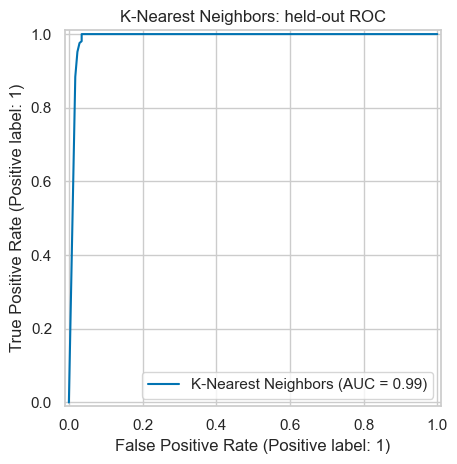

In [3]:
result = review.run_classifier('K-Nearest Neighbors', data)

## Naive Bayes
Train baseline, tune in five folds, display metrics and inspect held-out errors.

Best parameters: {'model__var_smoothing': 1e-10} | CV weighted F1: 0.9842031389418601


,Stage,Accuracy,Precision,Recall,F1_weighted,ROC_AUC
0,Baseline,0.98421,0.98466,0.98421,0.98418,0.99562
1,Tuned,0.98421,0.98466,0.98421,0.98418,0.99562


,Metric,Baseline,Tuned,Change
0,Accuracy,0.984211,0.984211,0.0
1,Precision,0.984655,0.984655,0.0
2,Recall,0.984211,0.984211,0.0
3,F1_weighted,0.984184,0.984184,0.0
4,ROC_AUC,0.995616,0.995616,0.0


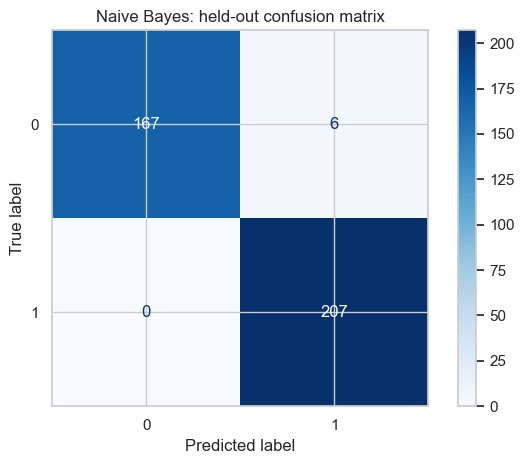

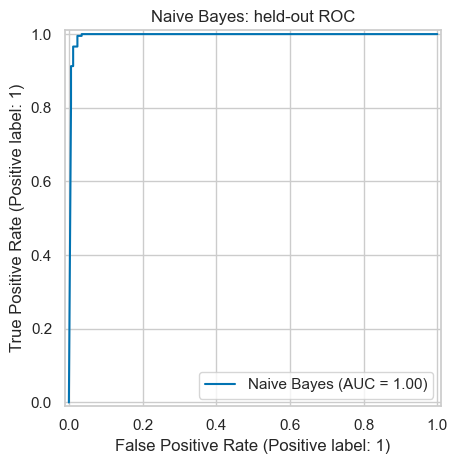

In [4]:
result = review.run_classifier('Naive Bayes', data)

## Decision Tree
Train baseline, tune in five folds, display metrics and inspect held-out errors.

Best parameters: {'model__max_depth': 3, 'model__min_samples_split': 2} | CV weighted F1: 0.983551172514279


,Stage,Accuracy,Precision,Recall,F1_weighted,ROC_AUC
0,Baseline,0.97368,0.97371,0.97368,0.97367,0.97300
1,Tuned,0.98158,0.98187,0.98158,0.98155,0.98809


,Metric,Baseline,Tuned,Change
0,Accuracy,0.973684,0.981579,0.007895
1,Precision,0.973712,0.981873,0.008161
2,Recall,0.973684,0.981579,0.007895
3,F1_weighted,0.973671,0.981554,0.007883
4,ROC_AUC,0.972997,0.988090,0.015093


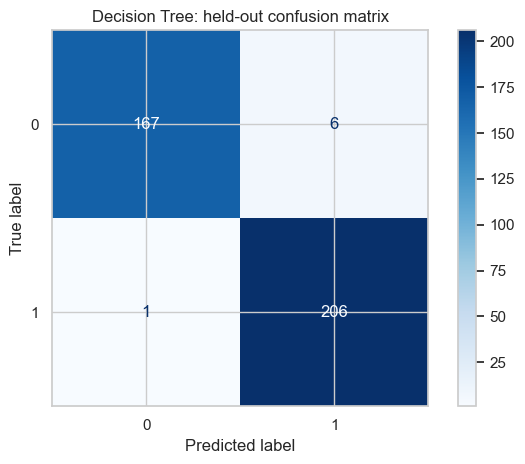

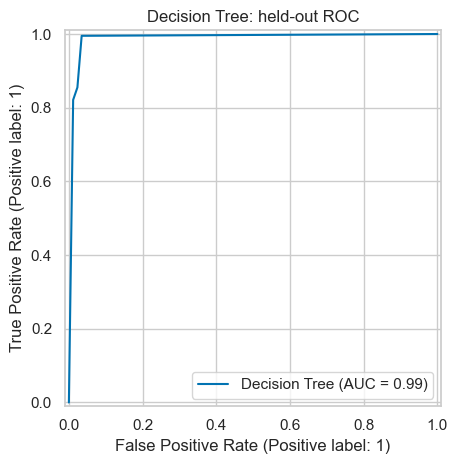

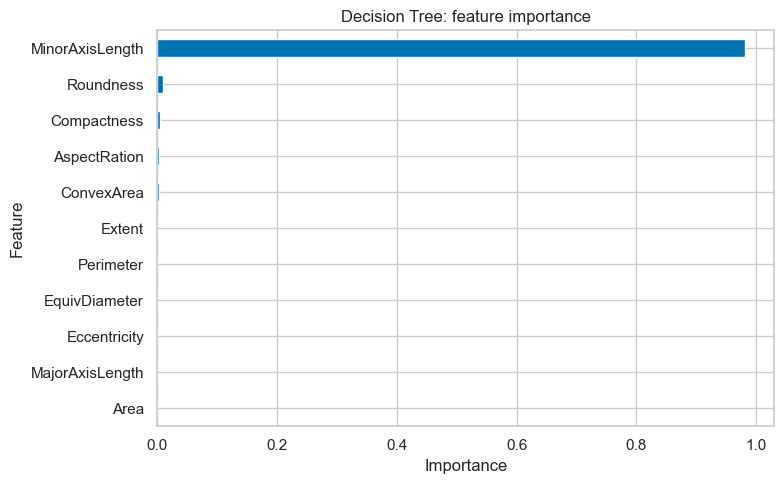

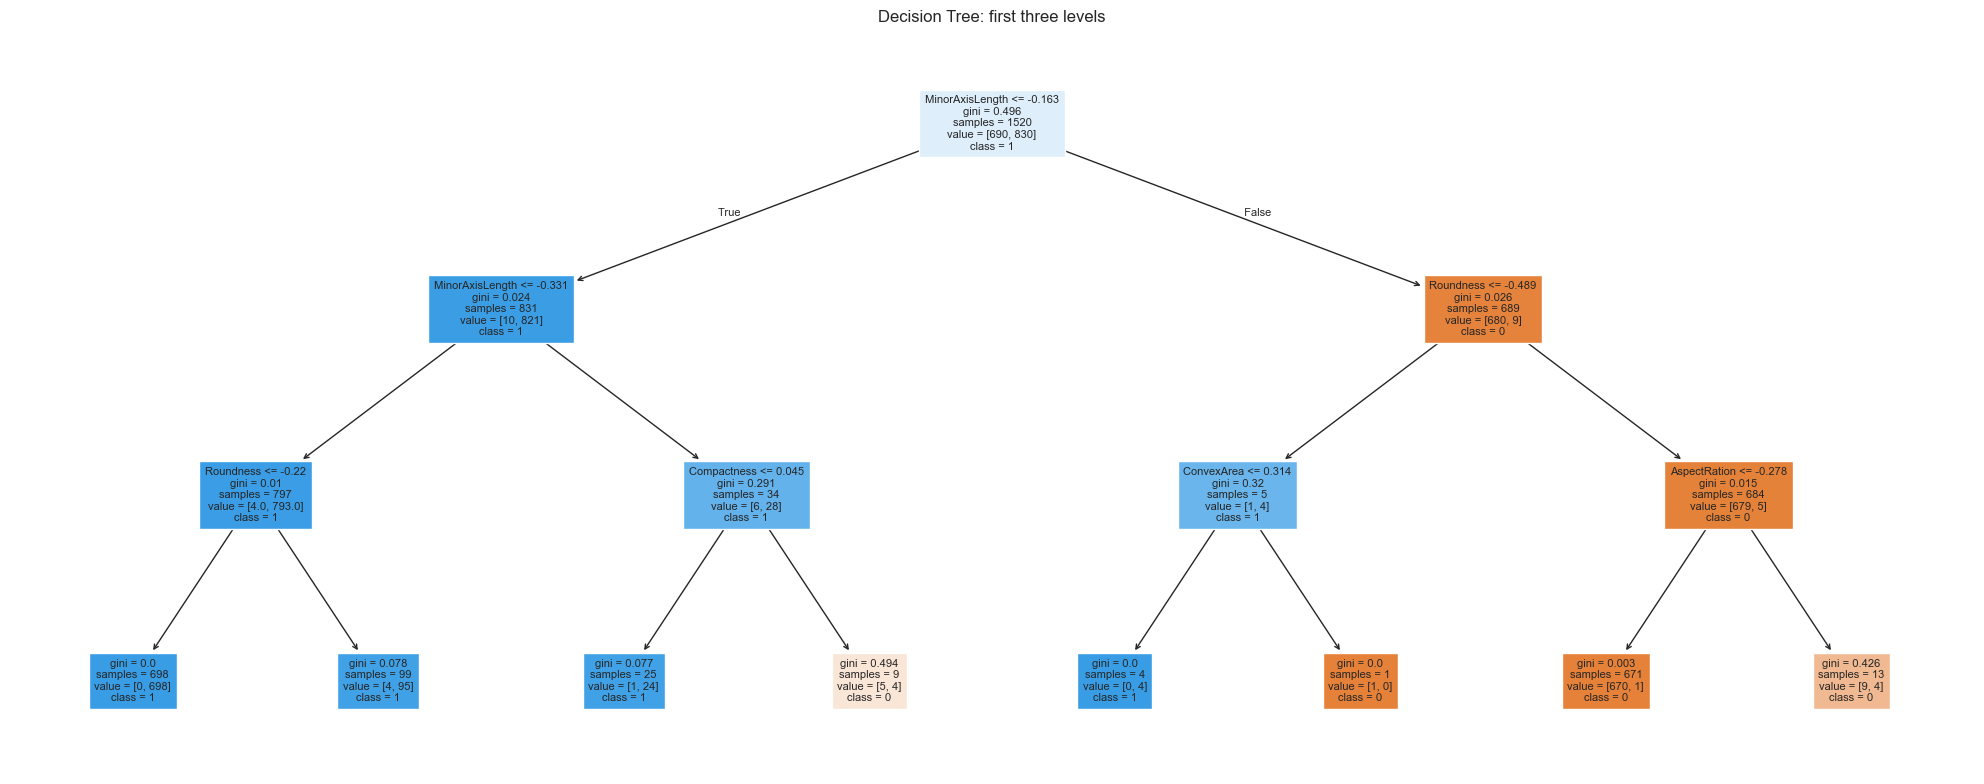

In [5]:
result = review.run_classifier('Decision Tree', data)

## Support Vector Machine
Train baseline, tune in five folds, display metrics and inspect held-out errors.

Best parameters: {'model__C': 1, 'model__kernel': 'linear'} | CV weighted F1: 0.9914453616460774


,Stage,Accuracy,Precision,Recall,F1_weighted,ROC_AUC
0,Baseline,0.98158,0.98187,0.98158,0.98155,0.99383
1,Tuned,0.98158,0.98187,0.98158,0.98155,0.99570


,Metric,Baseline,Tuned,Change
0,Accuracy,0.981579,0.981579,0.000000
1,Precision,0.981873,0.981873,0.000000
2,Recall,0.981579,0.981579,0.000000
3,F1_weighted,0.981554,0.981554,0.000000
4,ROC_AUC,0.993829,0.995700,0.001871


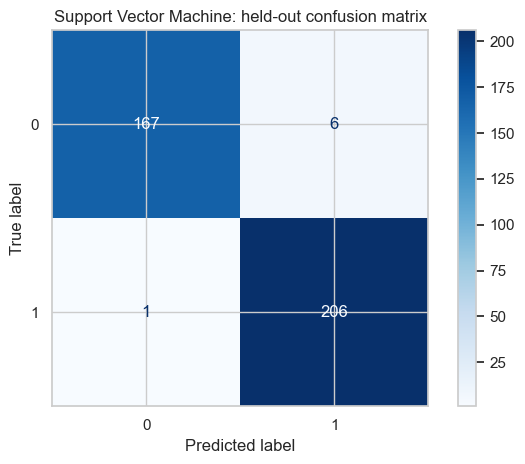

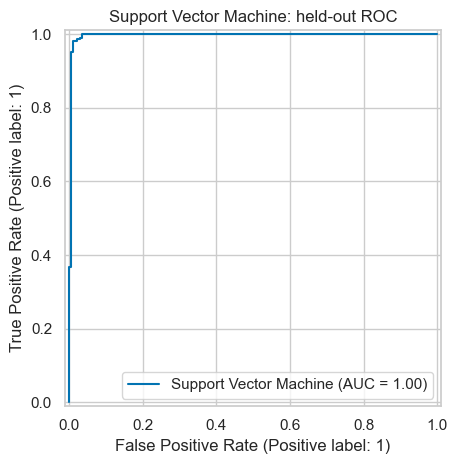

In [6]:
result = review.run_classifier('Support Vector Machine', data)

## Random Forest
Train baseline, tune in five folds, display metrics and inspect held-out errors.

Best parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 100} | CV weighted F1: 0.9881573685153908


,Stage,Accuracy,Precision,Recall,F1_weighted,ROC_AUC
0,Baseline,0.98158,0.98187,0.98158,0.98155,0.99405
1,Tuned,0.98158,0.98187,0.98158,0.98155,0.99405


,Metric,Baseline,Tuned,Change
0,Accuracy,0.981579,0.981579,0.0
1,Precision,0.981873,0.981873,0.0
2,Recall,0.981579,0.981579,0.0
3,F1_weighted,0.981554,0.981554,0.0
4,ROC_AUC,0.994052,0.994052,0.0


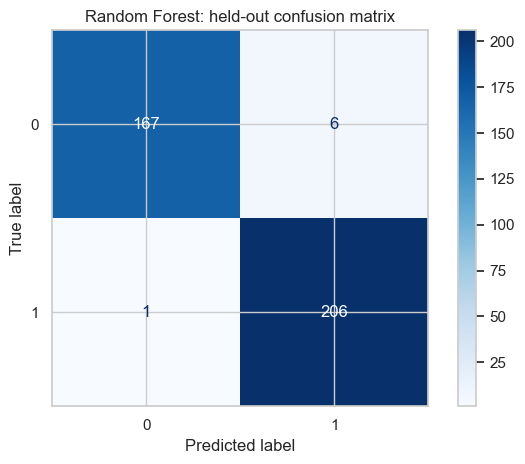

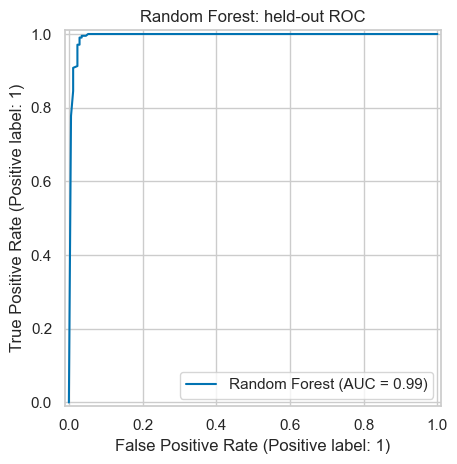

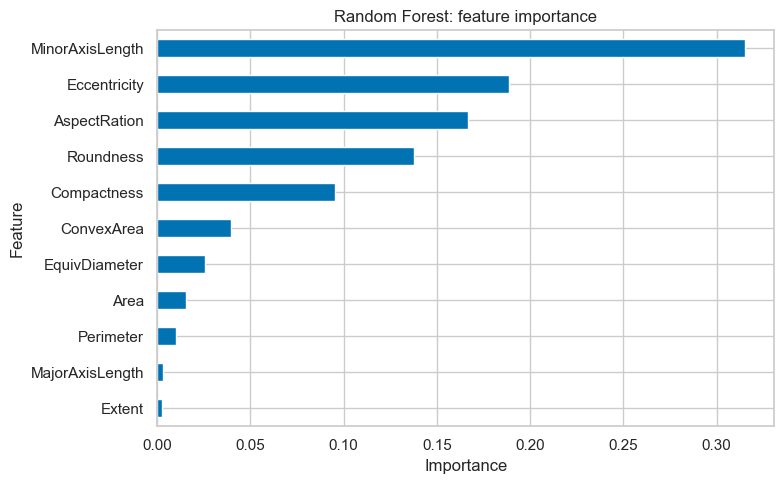

In [7]:
result = review.run_classifier('Random Forest', data)

## AdaBoost
Train baseline, tune in five folds, display metrics and inspect held-out errors.

Best parameters: {'model__learning_rate': 0.1, 'model__n_estimators': 200} | CV weighted F1: 0.9881609762973327


,Stage,Accuracy,Precision,Recall,F1_weighted,ROC_AUC
0,Baseline,0.98158,0.98187,0.98158,0.98155,0.99380
1,Tuned,0.98158,0.98187,0.98158,0.98155,0.99458


,Metric,Baseline,Tuned,Change
0,Accuracy,0.981579,0.981579,0.000000
1,Precision,0.981873,0.981873,0.000000
2,Recall,0.981579,0.981579,0.000000
3,F1_weighted,0.981554,0.981554,0.000000
4,ROC_AUC,0.993801,0.994583,0.000782


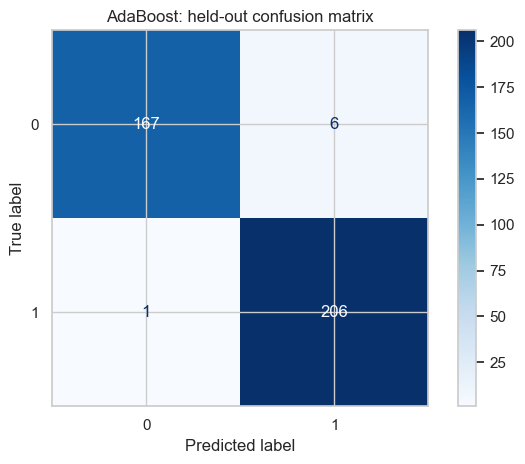

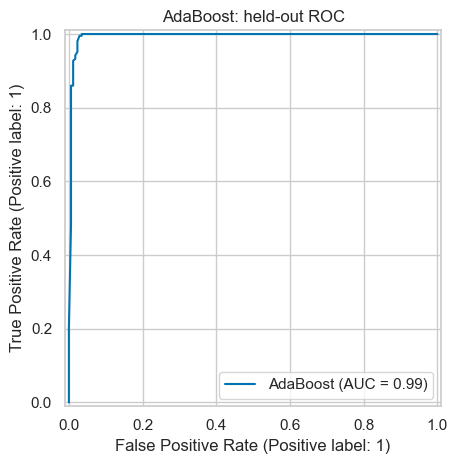

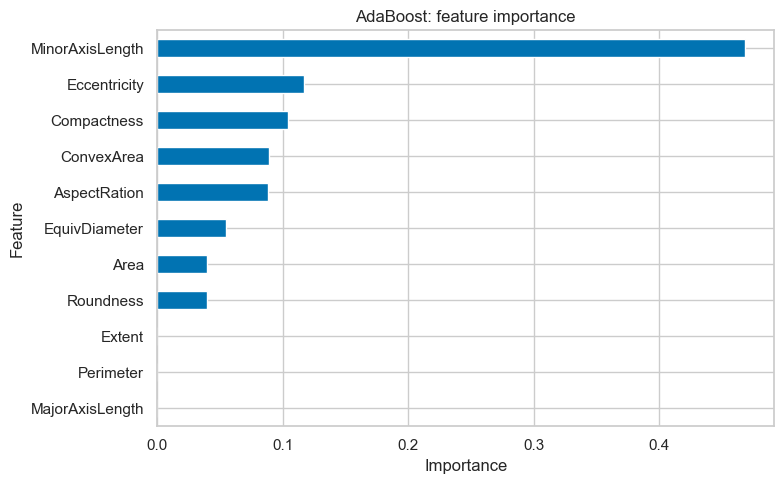

In [8]:
result = review.run_classifier('AdaBoost', data)

## Gradient Boosting
Train baseline, tune in five folds, display metrics and inspect held-out errors.

Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 100} | CV weighted F1: 0.9894741312315984


,Stage,Accuracy,Precision,Recall,F1_weighted,ROC_AUC
0,Baseline,0.98158,0.98187,0.98158,0.98155,0.99594
1,Tuned,0.98158,0.98187,0.98158,0.98155,0.99435


,Metric,Baseline,Tuned,Change
0,Accuracy,0.981579,0.981579,0.000000
1,Precision,0.981873,0.981873,0.000000
2,Recall,0.981579,0.981579,0.000000
3,F1_weighted,0.981554,0.981554,0.000000
4,ROC_AUC,0.995937,0.994345,-0.001592


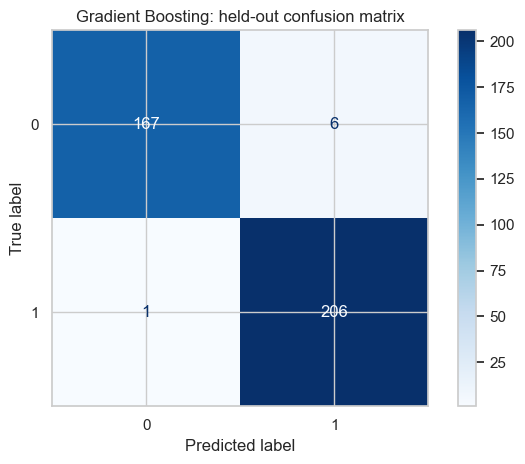

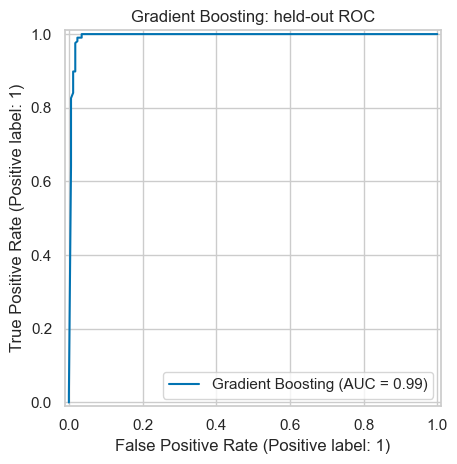

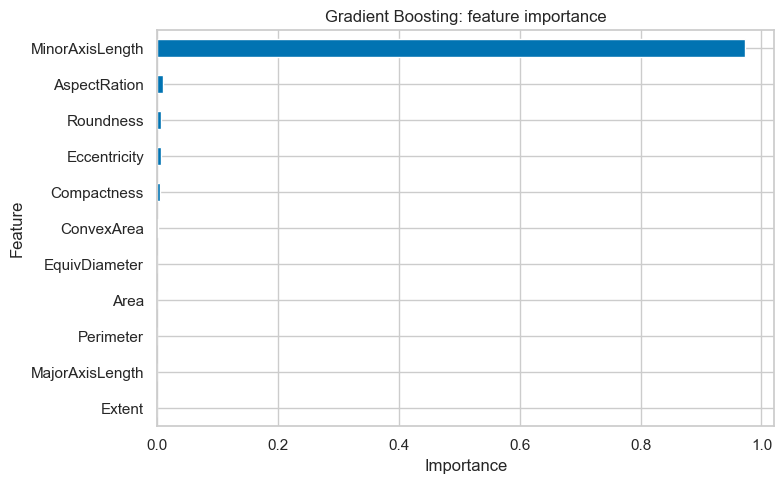

In [9]:
result = review.run_classifier('Gradient Boosting', data)

## Bagging
Train baseline, tune in five folds, display metrics and inspect held-out errors.

Best parameters: {'model__estimator__max_depth': None, 'model__max_samples': 1.0, 'model__n_estimators': 100} | CV weighted F1: 0.9861829209795546


,Stage,Accuracy,Precision,Recall,F1_weighted,ROC_AUC
0,Baseline,0.98158,0.98187,0.98158,0.98155,0.98221
1,Tuned,0.98158,0.98187,0.98158,0.98155,0.99172


,Metric,Baseline,Tuned,Change
0,Accuracy,0.981579,0.981579,0.000000
1,Precision,0.981873,0.981873,0.000000
2,Recall,0.981579,0.981579,0.000000
3,F1_weighted,0.981554,0.981554,0.000000
4,ROC_AUC,0.982212,0.991720,0.009508


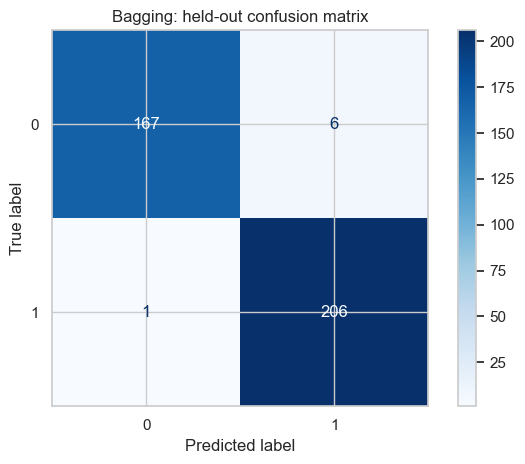

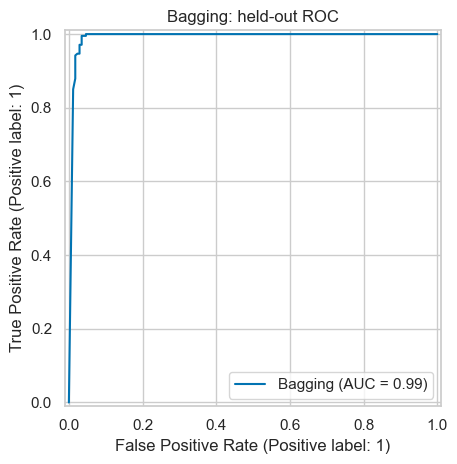

In [10]:
result = review.run_classifier('Bagging', data)

## MLP
Train baseline, tune in five folds, display metrics and inspect held-out errors.

Best parameters: {'model__activation': 'tanh', 'model__alpha': 0.0001, 'model__hidden_layer_sizes': (100, 50)} | CV weighted F1: 0.988150934598281


,Stage,Accuracy,Precision,Recall,F1_weighted,ROC_AUC
0,Baseline,0.97632,0.97632,0.97632,0.97631,0.99201
1,Tuned,0.98421,0.98466,0.98421,0.98418,0.99366


,Metric,Baseline,Tuned,Change
0,Accuracy,0.976316,0.984211,0.007895
1,Precision,0.976318,0.984655,0.008337
2,Recall,0.976316,0.984211,0.007895
3,F1_weighted,0.976310,0.984184,0.007874
4,ROC_AUC,0.992014,0.993661,0.001648


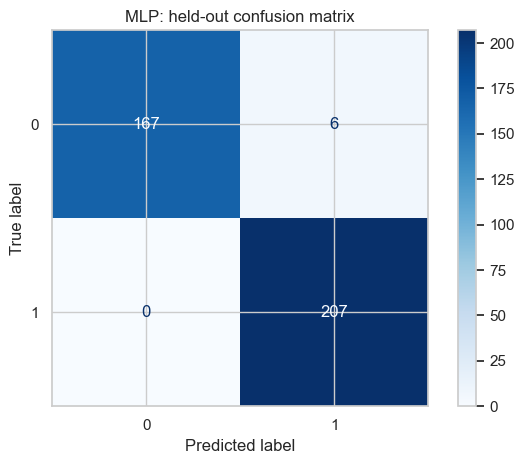

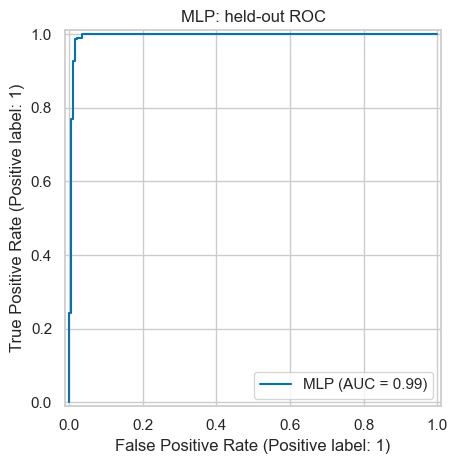

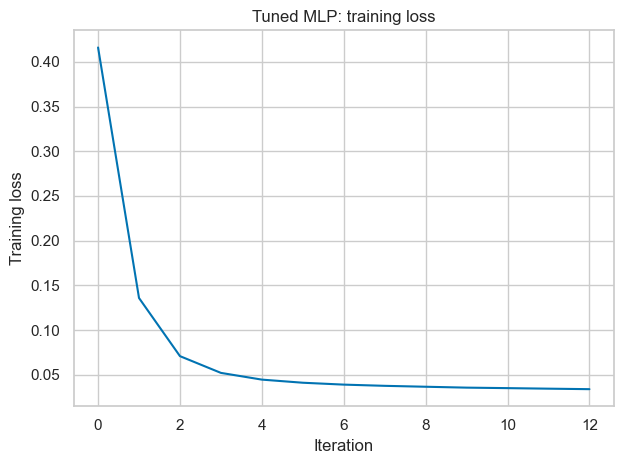

In [11]:
result = review.run_classifier('MLP', data)

## Consolidated comparison and final selection
Exactly ten algorithms and all five finite metrics are required. Dataset/split signatures must match. Rank by training CV weighted F1, show CV results for the top two and save the selected complete pipeline. Positive baseline-to-tuned changes are reported without assuming improvement.

In [12]:
classification_comparison = review.consolidate_classification(data)

Selected using highest training CV weighted F1: Support Vector Machine
Top-two CV reuses tuning folds; it is not an unbiased nested-CV estimate. The untouched holdout is the final evaluation.
Positive test metric changes: ['ROC_AUC']
If empty, the rubric improvement requirement remains unmet; do not claim improvement.


,CV_rank,Algorithm,Accuracy,Precision,Recall,F1_weighted,ROC_AUC,CV_F1_mean,CV_F1_std
0,1,Support Vector Machine,0.98158,0.98187,0.98158,0.98155,0.99570,0.99145,0.00263
1,2,Logistic Regression,0.98158,0.98187,0.98158,0.98155,0.99595,0.99079,0.00322
2,3,K-Nearest Neighbors,0.98158,0.98187,0.98158,0.98155,0.98951,0.99079,0.00246
3,4,Gradient Boosting,0.98158,0.98187,0.98158,0.98155,0.99435,0.98947,0.00383
4,5,AdaBoost,0.98158,0.98187,0.98158,0.98155,0.99458,0.98816,0.00533
5,6,Random Forest,0.98158,0.98187,0.98158,0.98155,0.99405,0.98816,0.00534
6,7,MLP,0.98421,0.98466,0.98421,0.98418,0.99366,0.98815,0.00395
7,8,Bagging,0.98158,0.98187,0.98158,0.98155,0.99172,0.98618,0.00483
8,9,Naive Bayes,0.98421,0.98466,0.98421,0.98418,0.99562,0.98420,0.00915
9,10,Decision Tree,0.98158,0.98187,0.98158,0.98155,0.98809,0.98355,0.00509


,Metric,Baseline,Tuned,Change
0,Accuracy,0.981579,0.981579,0.000000
1,Precision,0.981873,0.981873,0.000000
2,Recall,0.981579,0.981579,0.000000
3,F1_weighted,0.981554,0.981554,0.000000
4,ROC_AUC,0.993829,0.995700,0.001871


## Team-written interpretation required before submission
The guidelines (section 7.5) permit AI code scaffolding but reserve analysis and interpretation for the team. Write your own observations here after studying the visible outputs. This cell deliberately does not supply an AI-written interpretation.

- Explain the major plots, errors or overlapping segments using the actual evidence above.
- Discuss the selected hyperparameters, metric trade-offs and limitations.
- For classification, explain weighted precision/recall/F1, ROC-AUC, the confusion matrix, and whether tuning improved any metric.
- For clustering, justify k/linkage using the elbow/dendrogram and all three metrics; explain profiles in original units and projection limitations.

**Submission status: team interpretation is pending until these points are replaced with original observations.**